# 02. 데이터 수집과 구성 보기 — 전체 11단계 중 2단계

작업하며 주고받은 글(내가 셀마다 적은 칸과 클로드의 답변)은 빼고 코드 · 결과 · 결정만 남긴 판이다. 진행 방식은 README 「진행 방식」에 있다.

**이 단계에서 한 일과 정한 것** — 전력거래소(시간별 발전량) · 기상청(서울의 시간별 기온 · 습도 · 일사) · 전력통계정보시스템(EPSIS, 월별 발전량) · 공휴일 자료를 받아, 몇 줄 몇 칸인지와 빠지거나 겹친 시각이 있는지 봤다. 2023 ~ 2025년 LNG 발전량의 월 합계는 값이 잘못된 기간이 든 달을 빼면 EPSIS와 맞았다.

## 물음 — 이 데이터가 어떻게 생겼나

> **결정** — 2023·2025년은 그대로 쓰고, 2024년 2월 29일은 빼고, 2026년에 깨져서 온 날은 하루씩 따로 본다

## 판단 재료 — 받은 그대로의 데이터를 본다

네 덩어리이고 셀도 넷으로 나눠 두었다 — 위에서부터 차례로 실행한다: (1) KPX 시간별 파일의 모양·연료별 행 수·빠진 시각 (2) LNG 월 합계 vs EPSIS (3) 월별 그림 (4) 기온 파일과 2024 API 파일이 비어 있지 않은지.

In [164]:
# 전체 11단계 중 → 2단계 데이터 수집과 구성 보기 · 준비 — 아래 셀들이 쓸 경로와 함수를 만든다. 결과는 찍지 않는다
import os, glob                             # 폴더·파일 경로를 다루는 모듈과, 파일 이름을 한꺼번에 찾는 모듈
import pandas as pd                         # 표(데이터프레임)를 다루는 라이브러리
import matplotlib.pyplot as plt             # 그림 그리는 라이브러리
plt.rcParams["font.family"] = "AppleGothic" # 맥에서 그림 속 한글이 깨지지 않게
plt.rcParams["axes.unicode_minus"] = False  # 마이너스 부호가 깨지지 않게
pd.set_option("display.width", 160)         # 표가 줄바꿈 없이 넓게 보이게

ROOT = os.getcwd()                          # 지금 폴더(보통 notebooks/)에서 시작해
while not os.path.isdir(os.path.join(ROOT, "data")) and ROOT != os.path.dirname(ROOT):
    ROOT = os.path.dirname(ROOT)            # data 폴더가 보일 때까지 위로 올라간다 = 프로젝트 루트
RAW = os.path.join(ROOT, "data", "raw")     # 원자료 폴더

def load_kpx(year):                         # 연간 파일 한 해를 읽어 열 이름을 통일해 돌려주는 함수
    folder = os.path.join(RAW, "kpx")
    name = [f for f in os.listdir(folder) if f"{year}1231" in f][0]      # 파일명에 20231231 같은 기준일이 들어 있다
    df = pd.read_csv(os.path.join(folder, name), encoding="utf-8-sig")   # 맨 앞 BOM이 있는 utf-8
    df.columns = ["date", "hour", "fuel", "cap_mw", "mwh"]              # 해마다 열 이름이 달라서(공백·'원료원') 자리로 통일
    df["fuel"] = df["fuel"].str.strip()      # 연료 이름 앞뒤 공백 제거
    df["year"] = year                        # 어느 해 파일인지 표시
    return df

def load_api(year):                          # API로 받은 한 해를 읽어 같은 열 이름으로 돌려주는 함수
    파일 = [f for f in sorted(glob.glob(os.path.join(RAW, "api", f"{year}*.csv")))
            if os.path.getsize(f) >= 100]    # 100바이트 미만 = 0행으로 온 날이라 건너뛴다
    df = pd.concat([pd.read_csv(f) for f in 파일], ignore_index=True)     # 하루치 파일들을 위아래로 붙인다
    df = df.rename(columns={"fuelTpCd": "fuel", "amgo": "mwh"})          # 연간 파일과 같은 이름으로 바꾼다
    df["date"] = pd.to_datetime(df["tradeYmd"].astype(str))              # 20240101 을 날짜로
    df["hour"] = df["tradeNo"].astype(int)                               # 1~24 시간 표기 (연간 파일과 같다)
    df["year"] = year
    return df[["date", "hour", "fuel", "mwh", "year"]]

print("준비 끝 — 프로젝트 폴더:", ROOT)


준비 끝 — 프로젝트 폴더: /Users/kimchangju/vs코드 /개인 프로젝트/lng-project


In [165]:
# 전체 11단계 중 → 2단계 데이터 수집과 구성 보기 · 연간 파일 세 해(2023·2024·2025)를 읽어 몇 줄 몇 칸인지, 어떤 연료가 들어 있는지 본다
for 해 in (2023, 2024, 2025):                                             # 세 해를 하나씩
    folder = os.path.join(RAW, "kpx")
    name = [f for f in os.listdir(folder) if f"{해}1231" in f][0]
    원본 = pd.read_csv(os.path.join(folder, name), encoding="utf-8-sig")   # 파일을 끝까지 읽는다
    연료 = sorted(원본[원본.columns[2]].astype(str).str.strip().unique())    # 세 번째 열이 연료 이름이다
    print(f"[{해}] {원본.shape[0]:,}행 {원본.shape[1]}칸 · 열 이름 {list(원본.columns)}")
    print(f"       연료 {len(연료)}종: {', '.join(연료)}")

kpx = pd.concat([load_kpx(2023), load_kpx(2024), load_kpx(2025)], ignore_index=True)   # 세 해를 위아래로 붙인다
print("\n세 해 합친 모양 (행, 열):", kpx.shape)
print(kpx.dtypes)                            # 자료형 — 숫자여야 할 열이 문자(object)면 여기서 보인다
print(kpx.head(3))


[2023] 179,208행 5칸 · 열 이름 ['거래일자', '시간', '연료원', ' 설비용량(MW) ', ' 전력거래량(MWh) ']
       연료 21종: IGCC, LNG, 경유, 기타, 매립가스, 무연탄, 바이오SRF, 바이오가스, 바이오매스, 바이오중유, 부생가스, 수력, 양수, 연료전지, 원자력, 유연탄, 중유, 태양광, 폐기물, 풍력, 해양에너지
[2024] 110,544행 5칸 · 열 이름 ['거래일자', '시간', '원료원', '설비용량(MW)', '전력거래량(MWh)']
       연료 13종: IGCC, 급전가능 재생에너지, 매립가스, 바이오SRF, 바이오가스, 바이오매스, 바이오중유, 소수력, 수력, 연료전지, 태양광, 풍력, 해양에너지
[2025] 224,928행 5칸 · 열 이름 ['거래일자', '거래시간', '연료원별', '설비용량(MW)', '전력거래량(MWh)']
       연료 26종: IGCC, LNG, LPG, 가스압, 경유, 급전가능 재생에너지, 기타, 매립가스, 무연탄, 바이오SRF, 바이오가스, 바이오매스, 바이오중유, 부생가스, 소수력, 수력, 양수, 연료전지, 원자력, 유연탄, 전기저장장치(비중앙), 중유, 태양광, 폐기물, 풍력, 해양에너지

세 해 합친 모양 (행, 열): (514680, 6)
date       object
hour        int64
fuel       object
cap_mw    float64
mwh       float64
year        int64
dtype: object
         date  hour fuel   cap_mw      mwh  year
0  2023-01-01     1  원자력  24650.0  19561.0  2023
1  2023-01-01     2  원자력  24650.0  19561.0  2023
2  2023-01-01     3  원자력  24650.0  19562.0  2023


In [166]:
# 전체 11단계 중 → 2단계 데이터 수집과 구성 보기 · 연료별 행 수 — 8,760 = 365일 × 24시간이면 그 해에 빠짐없이 있는 것
print(kpx.groupby(["year", "fuel"]).size().unstack(0).fillna(0).astype(int))


year         2023  2024  2025
fuel                         
IGCC         8760  8784  8760
LNG          8760     0  8760
LPG             0     0  8760
가스압             0     0  8760
경유           8760     0  8760
급전가능 재생에너지      0  5136  8760
기타           8760     0  8760
매립가스         8760  8784  8760
무연탄          8760     0  8760
바이오SRF       4008  8784  8760
바이오가스        8760  8784  8760
바이오매스        8760  8784  8760
바이오중유        8760  8784  8760
부생가스         8760     0  8760
소수력             0  8784  8760
수력           8760  8784  8760
양수           8760     0  8760
연료전지         8760  8784  8760
원자력          8760     0  8760
유연탄          8760     0  8760
전기저장장치(비중앙)     0     0  5928
중유           8760     0  8760
태양광          8760  8784  8760
폐기물          8760     0  8760
풍력           8760  8784  8760
해양에너지        8760  8784  8760


In [167]:
# 전체 11단계 중 → 2단계 데이터 수집과 구성 보기 · LNG만 떼서 중복 시각·빠진 시각·기초통계를 본다 (2024년은 연간 파일에 없어 API에서 가져온다)
lng = kpx[kpx["fuel"] == "LNG"].copy()                                   # 연간 파일에서 LNG 행만
lng24 = load_api(2024); lng24 = lng24[lng24["fuel"] == "LNG"].copy()      # 2024년은 API에서 LNG만
lng = pd.concat([lng[["date","hour","mwh","year"]], lng24[["date","hour","mwh","year"]]], ignore_index=True)
lng["ts"] = pd.to_datetime(lng["date"]) + pd.to_timedelta(lng["hour"].astype(int) - 1, unit="h")  # 1~24시 표기를 0~23시 시각으로

print("LNG 행 수:", len(lng), "| 중복 시각:", lng["ts"].duplicated().sum())
for y in (2023, 2024, 2025):
    full = pd.date_range(f"{y}-01-01", f"{y}-12-31 23:00", freq="h")     # 그 해의 모든 시각 목록
    have = set(lng.loc[lng["year"] == y, "ts"])                           # 실제로 있는 시각
    print(f"{y}년 빠진 시각 수:", sum(1 for t in full if t not in have))
print("\nLNG 발전량(MWh) 기초통계 — 해별")
print(lng.groupby("year")["mwh"].describe().round(0))


LNG 행 수: 26280 | 중복 시각: 0
2023년 빠진 시각 수: 0
2024년 빠진 시각 수: 24
2025년 빠진 시각 수: 0

LNG 발전량(MWh) 기초통계 — 해별
       count     mean     std     min      25%      50%      75%      max
year                                                                     
2023  8760.0  17525.0  5205.0  5631.0  13504.0  17038.0  21054.0  36534.0
2024  8760.0  16770.0  7217.0   155.0  13030.0  17102.0  21563.0  37882.0
2025  8760.0  18177.0  5964.0  4838.0  13674.0  17785.0  22313.0  38033.0


In [168]:
# 전체 11단계 중 → 2단계 데이터 수집과 구성 보기 · 시간별 LNG 월 합계를 EPSIS 월별 표와 대 본다 · 앞 셀들을 먼저 실행한 뒤에 돌린다
cols = ["기간","원자력","유연탄","무연탄","석탄계","유류","LNG","양수","연료전지","석탄가스화","태양","풍력",
        "수력","해양","바이오","폐기물","신재생계","기타","전력시장계","PPA계","합계"]           # 머리글 두 줄을 한 줄 이름으로
ep = pd.read_csv(os.path.join(RAW, "epsis_fuel_monthly.csv"), encoding="cp949", skiprows=2, header=None, names=cols)
ep["month"] = pd.to_datetime(ep["기간"], format="%Y/%m")   # '2026/07' 같은 글자를 날짜로
ep = ep.sort_values("month").reset_index(drop=True)          # 오래된 달부터 · 줄 번호도 0부터 다시 매긴다
print("EPSIS 표 기간:", ep["month"].min().date(), "~", ep["month"].max().date(), "| 행 수:", len(ep))

monthly = lng.groupby(lng["ts"].dt.to_period("M"))["mwh"].sum().div(1000).rename("우리_GWh")   # 시간별 MWh를 달로 합쳐 GWh로
cmp = ep.set_index(ep["month"].dt.to_period("M"))["LNG"].rename("EPSIS_GWh").to_frame().join(monthly, how="inner")
cmp["차이_%"] = ((cmp["우리_GWh"] - cmp["EPSIS_GWh"]) / cmp["EPSIS_GWh"] * 100).round(2)   # 0에 가까워야 같은 자료
print("\n시간별 LNG 월 합계 vs EPSIS 월별 표 (GWh) — 2023·2024·2025")
print(cmp.round(1).to_string())


EPSIS 표 기간: 2002-01-01 ~ 2026-07-01 | 행 수: 295

시간별 LNG 월 합계 vs EPSIS 월별 표 (GWh) — 2023·2024·2025
         EPSIS_GWh   우리_GWh  차이_%
2023-01    15038.9  15038.9   0.0
2023-02    13311.3  13311.3   0.0
2023-03    13777.9  13778.0   0.0
2023-04    11550.8  11550.8  -0.0
2023-05    11431.9  11431.9   0.0
2023-06    11686.2  11686.2  -0.0
2023-07    13568.5  13568.5   0.0
2023-08    14306.5  14306.5   0.0
2023-09    12517.0  12517.1   0.0
2023-10    10793.3  10793.3  -0.0
2023-11    11890.2  11899.6   0.1
2023-12    13628.3  13636.9   0.1
2024-01    15676.0  15676.0   0.0
2024-02    12781.6  12271.5  -4.0
2024-03    14385.3  14385.4   0.0
2024-04    11626.5  11654.2   0.2
2024-05    11969.0  11968.6  -0.0
2024-06    12715.9  12730.8   0.1
2024-07    15002.8  15004.9   0.0
2024-08    16690.9    311.0 -98.1
2024-09    13512.2  13514.4   0.0
2024-10    11842.8  11862.2   0.2
2024-11    12772.7  12772.7   0.0
2024-12    14754.6  14754.6   0.0
2025-01    15345.2  15345.2   0.0
2025-02    14953.8

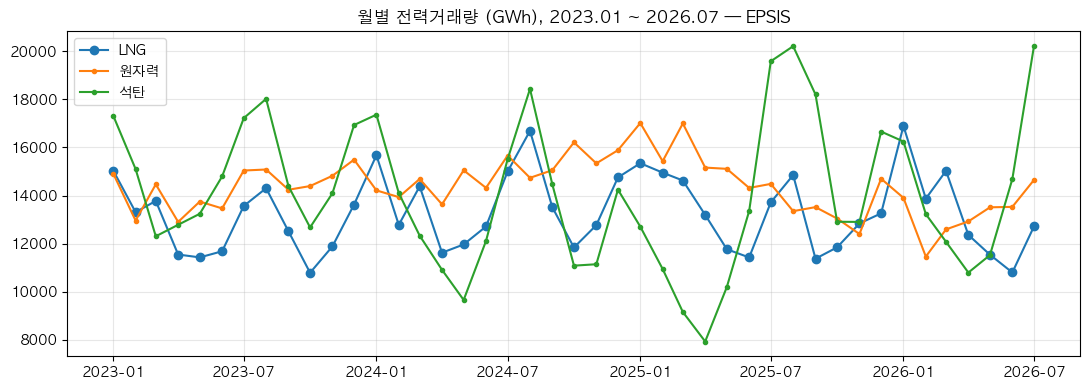

In [169]:
# 전체 11단계 중 → 2단계 데이터 수집과 구성 보기 · 월별 LNG·원전·석탄 그림 (EPSIS 기준, 2023.01~2026.07) · 앞 셀들을 먼저 실행한 뒤에 돌린다
# ── 그림 — 월별 LNG·원전·석탄, 2023.01~2026.07 (EPSIS 기준) ───────────
recent = ep[ep["month"] >= "2023-01-01"]
plt.figure(figsize=(11, 4))
plt.plot(recent["month"], recent["LNG"], marker="o", label="LNG")
plt.plot(recent["month"], recent["원자력"], marker=".", label="원자력")
plt.plot(recent["month"], recent["석탄계"], marker=".", label="석탄")
plt.title("월별 전력거래량 (GWh), 2023.01 ~ 2026.07 — EPSIS")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()


In [170]:
# 전체 11단계 중 → 2단계 데이터 수집과 구성 보기 · ASOS 기온과 API 파일 — 있는지·비었는지 본다 · 앞 셀들을 먼저 실행한 뒤에 돌린다
asos_dir = os.path.join(RAW, "asos")
asos = pd.concat([pd.read_csv(os.path.join(asos_dir, f), encoding="utf-8-sig")
                  for f in sorted(os.listdir(asos_dir)) if f.endswith(".csv")], ignore_index=True)   # 달마다 한 파일을 하나로
print("ASOS 행 수:", len(asos), "| 기간:", asos["tm"].min(), "~", asos["tm"].max())
for col in ["ta", "hm", "ws", "icsr"]:        # 기온·습도·풍속·일사
    if col in asos.columns:
        print(f"  {col} 빈 칸 수: {asos[col].isna().sum()}", "(일사는 밤에 비는 것이 정상)" if col == "icsr" else "")

print("\nAPI로 받은 해 — 하루 192행(연료 8종 × 24시간)이 아닌 날")
for 해 in (2024, 2026):
    파일 = sorted(glob.glob(os.path.join(RAW, "api", f"{해}*.csv")))
    빈 = [os.path.basename(f)[:8] for f in 파일 if os.path.getsize(f) < 100]          # 100바이트 미만 = 0행으로 온 날
    표 = pd.concat([pd.read_csv(f) for f in 파일 if os.path.getsize(f) >= 100], ignore_index=True)
    줄수 = 표.groupby("tradeYmd").size(); 이상 = 줄수[줄수 != 192]
    print(f"  {해}년 — 파일 {len(파일)}개 · 0행으로 온 날 {len(빈)}일 {빈} · 192행이 아닌 날 {len(이상)}일")
    for 행수, 날들 in 이상.groupby(이상).groups.items():                              # 행 수가 같은 날끼리 묶어서 본다
        print(f"      {행수}행으로 온 날 {len(날들)}일: {min(날들)} ~ {max(날들)}")


ASOS 행 수: 32136 | 기간: 2023-01-01 00:00 ~ 2026-08-31 23:00
  ta 빈 칸 수: 0 
  hm 빈 칸 수: 0 
  ws 빈 칸 수: 68 
  icsr 빈 칸 수: 14444 (일사는 밤에 비는 것이 정상)

API로 받은 해 — 하루 192행(연료 8종 × 24시간)이 아닌 날
  2024년 — 파일 366개 · 0행으로 온 날 1일 ['20240229'] · 192행이 아닌 날 31일
      120행으로 온 날 31일: 20240801 ~ 20240831
  2026년 — 파일 191개 · 0행으로 온 날 1일 ['20260517'] · 192행이 아닌 날 15일
      48행으로 온 날 14일: 20260503 ~ 20260516
      120행으로 온 날 1일: 20260502 ~ 20260502


## 2026년은 어디까지 받았나

위 셀들이 본 것은 학습과 채점에 쓸 2023·2024·2025년입니다. 2026년은 예측한 값과 비교할 해라서 따로 봅니다. 아직 받는 중이라 다른 해와 평균을 대 보면 오해를 부릅니다 — 1~7월만 있어서 여름이 절반만 들어가 있습니다. 그래서 여기서는 비교하지 않고 지금 상태만 봅니다.

아래 셀은 어디까지 받았는지와, 달을 다 받은 달의 LNG 합계가 EPSIS 월별 표와 맞는지를 찍습니다.

In [171]:
# 전체 11단계 중 → 2단계 데이터 수집과 구성 보기 · 2026년은 어디까지 받았고 달 합계가 EPSIS와 맞는지 본다 · 앞 셀들을 먼저 실행한 뒤에 돌린다
lng26 = load_api(2026)                                                    # API로 받은 2026년 전체
lng26 = lng26[lng26["fuel"] == "LNG"].copy()                              # LNG 행만
lng26["ts"] = pd.to_datetime(lng26["date"]) + pd.to_timedelta(lng26["hour"].astype(int) - 1, unit="h")
print("2026년 LNG —", lng26["ts"].min().strftime("%m-%d"), "~", lng26["ts"].max().strftime("%m-%d"),
      f"· {len(lng26)}시각 · 중복 {lng26['ts'].duplicated().sum()}개")

표 = lng26.groupby(lng26["ts"].dt.strftime("%Y%m")).agg(받은시각=("mwh", "size"), 우리_GWh=("mwh", "sum"))
표["우리_GWh"] = (표["우리_GWh"] / 1000).round(1)                          # MWh를 GWh로
표["그달시각"] = [pd.Period(m, freq="M").days_in_month * 24 for m in 표.index]   # 그 달 전체 시각 수
표["다받음"] = ["예" if a == b else "아니오" for a, b in zip(표["받은시각"], 표["그달시각"])]
표["EPSIS_GWh"] = ep.set_index(ep["month"].dt.strftime("%Y%m"))["LNG"].round(1)   # 같은 달의 EPSIS 값
표["차이_%"] = ((표["우리_GWh"] - 표["EPSIS_GWh"]) / 표["EPSIS_GWh"] * 100).round(2)
print("\n2026년 월별 LNG — 우리가 받은 것과 EPSIS 월별 표")
print(표[["받은시각", "그달시각", "다받음", "우리_GWh", "EPSIS_GWh", "차이_%"]].to_string())


2026년 LNG — 01-01 ~ 07-10 · 4224시각 · 중복 0개

2026년 월별 LNG — 우리가 받은 것과 EPSIS 월별 표
        받은시각  그달시각  다받음   우리_GWh  EPSIS_GWh   차이_%
ts                                                
202601   744   744    예  16895.9    16895.9   0.00
202602   672   672    예  13873.5    13873.5   0.00
202603   744   744    예  15028.6    15028.6   0.00
202604   720   720    예  12366.1    12366.1   0.00
202605   384   744  아니오   5799.3    11542.9 -49.76
202606   720   720    예  10790.8    10804.4  -0.13
202607   240   744  아니오   3800.0    12717.1 -70.12


## 물음 1 — 이상하게 결과가 나온 날 구성요소는?

> **결정** — 120행인 날은 무연탄·원자력·유전이 빠진 5종이고, 48행인 날은 수력·양수뿐이라 LNG가 없어서 못 쓴다

In [172]:
# 전체 11단계 중 → 2단계 데이터 수집과 구성 보기 · 물음 1 — 행 수가 네 가지(192·120·48·0)로 오는데 각각 무엇이 들어 있나 · 앞 셀들을 먼저 실행한 뒤에 돌린다
기준 = sorted(pd.read_csv(os.path.join(RAW, "api", "20240731.csv"))["fuelTpCd"].unique())   # 정상인 날에 오는 연료 8종
볼날 = [("20240731", "정상 기준"), ("20240801", "120행"), ("20260502", "120행"),
        ("20260503", "48행"), ("20240229", "0행")]

줄 = []                                                                   # 먼저 다섯 날을 한 표로 요약한다
상세 = {}
for ymd, 표시 in 볼날:
    경로 = os.path.join(RAW, "api", f"{ymd}.csv")
    크기 = os.path.getsize(경로)
    if 크기 < 100:                                                         # 100바이트 미만 = 표로 못 읽는 날
        줄.append({"날짜": ymd, "": 표시, "바이트": 크기, "행": 0, "연료종수": 0,
                   "빠진연료": ", ".join(기준), "LNG_하루합": None})
        상세[ymd] = open(경로, encoding="utf-8-sig").read()
        continue
    d = pd.read_csv(경로)
    있는 = sorted(d["fuelTpCd"].unique())
    빠진 = [f for f in 기준 if f not in 있는]
    lng = d.loc[d["fuelTpCd"] == "LNG", "amgo"].sum()
    줄.append({"날짜": ymd, "": 표시, "바이트": 크기, "행": len(d), "연료종수": len(있는),
               "빠진연료": ", ".join(빠진) if 빠진 else "없음", "LNG_하루합": round(lng)})
    상세[ymd] = d.groupby("fuelTpCd")["amgo"].agg(["size", "sum"]).round(0).rename(columns={"size": "행", "sum": "하루합_MWh"})

정상2026 = sorted(pd.read_csv(os.path.join(RAW, "api", "20260501.csv"))["fuelTpCd"].unique())  # 2026년 정상인 날
print("정상인 날에 오는 연료 8종:", 기준)
print("2026년 정상인 날(5월 1일)도 같은 8종인가:", 정상2026 == 기준, "— 같으니 기준은 2024년 하나로 둔다")
print("행 수는 연료 종수 × 24시간이다. 192행=8종 · 120행=5종 · 48행=2종 · 0행=아무것도 없음")
print()
print(pd.DataFrame(줄).to_string(index=False))

print("\n날마다 연료별로 자세히")
for ymd, 표시 in 볼날:
    print(f"\n[{ymd}] {표시}")
    print(상세[ymd] if not isinstance(상세[ymd], str) else f"  파일에 든 글자: {상세[ymd]!r}")


정상인 날에 오는 연료 8종: ['LNG', '무연탄', '수력', '신재생·기타', '양수', '원자력', '유연탄', '유전']
2026년 정상인 날(5월 1일)도 같은 8종인가: True — 같으니 기준은 2024년 하나로 둔다
행 수는 연료 종수 × 24시간이다. 192행=8종 · 120행=5종 · 48행=2종 · 0행=아무것도 없음

      날짜        바이트   행  연료종수                                   빠진연료  LNG_하루합
20240731 정상 기준 6368 192     8                                     없음 471306.0
20240801  120행 3899 120     5                           무연탄, 원자력, 유전   9642.0
20260502  120행 3851 120     5                           무연탄, 원자력, 유전   1047.0
20260503   48행 1410  48     2         LNG, 무연탄, 신재생·기타, 원자력, 유연탄, 유전      0.0
20240229    0행    4   0     0 LNG, 무연탄, 수력, 신재생·기타, 양수, 원자력, 유연탄, 유전      NaN

날마다 연료별로 자세히

[20240731] 정상 기준
           행   하루합_MWh
fuelTpCd              
LNG       24  471306.0
무연탄       24    7646.0
수력        24   19266.0
신재생·기타    24  110473.0
양수        24   11159.0
원자력       24  465688.0
유연탄       24  578091.0
유전        24     130.0

[20240801] 120행
           행   하루합_MWh
fuelTpCd              
LNG       24  

## 물음 2 — 해마다 연료별 비중이 어떻게 달라졌나

> **결정** — 없음. 2024년은 석탄이 줄고 LNG가 늘었고, 2025년은 반대였다는 것까지 봤다

In [173]:
# 전체 11단계 중 → 2단계 데이터 수집과 구성 보기 · 물음 2 — 해마다 연료별 비중이 어떻게 달라졌나 (EPSIS 연간 합계) · 앞 셀들을 먼저 실행한 뒤에 돌린다
연 = ep[ep["month"].dt.year.between(2023, 2025)].groupby(ep["month"].dt.year)[
     ["LNG", "원자력", "석탄계", "신재생계", "전력시장계"]].sum().round(0)          # 해마다 연료별 연간 합계
print("연간 전력거래량 (GWh) — EPSIS")
print(연.to_string())

몫 = (연[["LNG", "원자력", "석탄계", "신재생계"]].div(연["전력시장계"], axis=0) * 100).round(1)
print("\n전력시장계에서 차지하는 몫 (%)")
print(몫.to_string())

print("\n전년 대비 증감 (%) — 전체가 는 것보다 덜 늘면 몫은 줄어든다")
print((연.pct_change() * 100).round(1).dropna().to_string())


연간 전력거래량 (GWh) — EPSIS
            LNG       원자력       석탄계     신재생계     전력시장계
month                                                 
2023   153501.0  171550.0  178897.0  33697.0  544482.0
2024   163730.0  178749.0  161387.0  37818.0  549387.0
2025   159227.0  175549.0  164790.0  41082.0  547119.0

전력시장계에서 차지하는 몫 (%)
        LNG   원자력   석탄계  신재생계
month                        
2023   28.2  31.5  32.9   6.2
2024   29.8  32.5  29.4   6.9
2025   29.1  32.1  30.1   7.5

전년 대비 증감 (%) — 전체가 는 것보다 덜 늘면 몫은 줄어든다
       LNG  원자력  석탄계  신재생계  전력시장계
month                            
2024   6.7  4.2 -9.8  12.2    0.9
2025  -2.8 -1.8  2.1   8.6   -0.4


## 물음 3 — 일사(icsr) 빈 칸이 달마다 몇 %인가

> **결정** — 일사 빈 칸은 달마다 37.5~54.7%이고, 밤이라서 정상이다. 더 보지 않는다

In [174]:
# 전체 11단계 중 → 2단계 데이터 수집과 구성 보기 · 물음 3 — 일사(icsr) 빈 칸이 달마다 몇 %인가 · 앞 셀들을 먼저 실행한 뒤에 돌린다
asos["ts"] = pd.to_datetime(asos["tm"])                                            # 글자로 된 시각을 날짜로
asos["월"] = asos["ts"].dt.month                                                    # 달만 뗀다
표 = asos.groupby("월").agg(시각수=("icsr", "size"), 일사빈칸=("icsr", lambda s: s.isna().sum()))
표["빈칸_%"] = (표["일사빈칸"] / 표["시각수"] * 100).round(1)
표["값있는시각_하루평균"] = ((표["시각수"] - 표["일사빈칸"]) / (표["시각수"] / 24)).round(1)   # 하루 몇 시간에 값이 있나
print("달마다 일사(icsr) 빈 칸 — 밤이라 비는 것이면 여름이 적고 겨울이 많아야 한다")
print(표.to_string())

print("\n기온(ta)·습도(hm)·풍속(ws) 빈 칸 — 달별 (0이면 빈 칸 없음)")
print(asos.groupby("월")[["ta", "hm", "ws"]].apply(lambda g: g.isna().sum()).to_string())


달마다 일사(icsr) 빈 칸 — 밤이라 비는 것이면 여름이 적고 겨울이 많아야 한다
     시각수  일사빈칸  빈칸_%  값있는시각_하루평균
월                               
1   2976  1612  54.2        11.0
2   2712  1376  50.7        11.8
3   2976  1394  46.8        12.8
4   2880  1161  40.3        14.3
5   2976  1116  37.5        15.0
6   2880  1080  37.5        15.0
7   2976  1116  37.5        15.0
8   2976  1126  37.8        14.9
9   2160   994  46.0        13.0
10  2232  1083  48.5        12.4
11  2160  1166  54.0        11.0
12  2232  1220  54.7        10.9

기온(ta)·습도(hm)·풍속(ws) 빈 칸 — 달별 (0이면 빈 칸 없음)
    ta  hm  ws
월             
1    0   0   0
2    0   0   0
3    0   0  31
4    0   0   0
5    0   0   0
6    0   0   0
7    0   0   0
8    0   0   0
9    0   0   0
10   0   0   0
11   0   0   0
12   0   0  37


## 물음 4 — 깨진 날의 LNG 값을 그대로 쓸 수 있나

> **결정** — 2024년 8월과 2026년 5월 2일의 LNG는 모델링에 쓰지 않는다

In [175]:
# 전체 11단계 중 → 2단계 데이터 수집과 구성 보기 · 물음 4 — 깨진 날과 정상인 날의 시간별 LNG를 나란히 놓는다 · 앞 셀들을 먼저 실행한 뒤에 돌린다
볼날 = ["20240731", "20240801", "20240815", "20240901", "20260501", "20260502"]   # 정상·깨짐·깨짐·정상 · 정상·깨짐
모음 = {}
for ymd in 볼날:
    d = pd.read_csv(os.path.join(RAW, "api", f"{ymd}.csv"))
    lng = d[d["fuelTpCd"] == "LNG"].astype({"tradeNo": int, "amgo": float}).sort_values("tradeNo")
    모음[ymd] = lng.set_index("tradeNo")["amgo"]                                   # 1~24시를 줄 번호로

표 = pd.DataFrame(모음).round(0); 표.index.name = "시각"
print("시간별 LNG (MWh) — 정상인 날과 깨진 날을 나란히")
print(표.to_string())
print("\n하루 합계 (MWh)")
for k, v in 모음.items():
    print(f"  {k}: {v.sum():>10,.0f}")


시간별 LNG (MWh) — 정상인 날과 깨진 날을 나란히
    20240731  20240801  20240815  20240901  20260501  20260502
시각                                                            
1    13488.0     405.0     450.0   13088.0   18026.0      53.0
2    10835.0     355.0     379.0   11948.0   15984.0      54.0
3     9482.0     294.0     382.0   11385.0   15517.0      56.0
4     9273.0     295.0     390.0   10627.0   15144.0      56.0
5     9329.0     295.0     389.0   10295.0   14672.0      57.0
6     9750.0     297.0     392.0   10389.0   15642.0      57.0
7    11737.0     302.0     395.0   10252.0   17679.0      58.0
8    15123.0     316.0     396.0   10259.0   16922.0      58.0
9    18440.0     345.0     388.0   10479.0   13630.0      55.0
10   21061.0     371.0     379.0   11421.0   10583.0      50.0
11   22659.0     368.0     388.0   12738.0    8581.0      47.0
12   22744.0     359.0     420.0   13372.0    7449.0      44.0
13   22577.0     357.0     423.0   13785.0    6874.0      41.0
14   23695.0     352.0

## 물음 5 — 풍속(ws) 빈 칸 68개가 어느 날인가

> **결정** — 2023년 12월 10·11일과 2024년 3월 11·12일, 네 날에 몰려 있다. 이어져 있는지는 물음 8에서 본다

In [176]:
# 전체 11단계 중 → 2단계 데이터 수집과 구성 보기 · 물음 5 — 풍속(ws) 빈 칸이 어느 해 어느 날 몇 시인가 · 앞 셀들을 먼저 실행한 뒤에 돌린다
빈 = asos[asos["ws"].isna()].copy()                                                # 풍속이 비어 있는 행만
빈["ts"] = pd.to_datetime(빈["tm"])
print("ASOS는 한 시간에 한 줄이다. 하루 24줄 · 한 달 720~744줄 ·", f"전체 {len(asos):,}줄")
print(f"풍속 빈 칸: {len(빈)}개\n")
print("날짜별 빈 칸 수")
print(빈.groupby(빈["ts"].dt.strftime("%Y-%m-%d")).size().to_string())
print("\n빈 칸이 난 시각 (앞 24개)")
print(", ".join(빈["ts"].dt.strftime("%m-%d %H시").head(24)))


ASOS는 한 시간에 한 줄이다. 하루 24줄 · 한 달 720~744줄 · 전체 32,136줄
풍속 빈 칸: 68개

날짜별 빈 칸 수
ts
2023-12-10    23
2023-12-11    14
2024-03-11    13
2024-03-12    18

빈 칸이 난 시각 (앞 24개)
12-10 01시, 12-10 02시, 12-10 03시, 12-10 04시, 12-10 05시, 12-10 06시, 12-10 07시, 12-10 08시, 12-10 09시, 12-10 10시, 12-10 11시, 12-10 12시, 12-10 13시, 12-10 14시, 12-10 15시, 12-10 16시, 12-10 17시, 12-10 18시, 12-10 19시, 12-10 20시, 12-10 21시, 12-10 22시, 12-10 23시, 12-11 00시


## 물음 6 — 48행인 날의 LNG는 어떻게 나오나

> **결정** — 5월 2일(값이 틀림)과 3·4일(LNG 없음)은 결측으로 처리한다

In [177]:
# 전체 11단계 중 → 2단계 데이터 수집과 구성 보기 · 물음 6 — 5월 1일(192행)·2일(120행)·3일·4일(48행)의 시간별 LNG를 한 표에 · 앞 셀들을 먼저 실행한 뒤에 돌린다
볼날 = ["20260501", "20260502", "20260503", "20260504"]                     # 192행 · 120행 · 48행 · 48행
모음 = {}
for ymd in 볼날:
    d = pd.read_csv(os.path.join(RAW, "api", f"{ymd}.csv"))
    lng = d[d["fuelTpCd"] == "LNG"]                                          # LNG 행만
    if len(lng) == 0:                                                        # LNG가 아예 없는 날
        모음[ymd] = pd.Series(dtype=float); continue
    모음[ymd] = lng.astype({"tradeNo": int, "amgo": float}).sort_values("tradeNo").set_index("tradeNo")["amgo"]

표 = pd.DataFrame(모음).round(0); 표.index.name = "시각"
print("시간별 LNG (MWh) — 빈 칸은 그 날 LNG 행이 아예 없다는 뜻")
print(표.to_string())
print("\n날마다 LNG 행이 몇 개 왔나:", {k: len(v) for k, v in 모음.items()})


시간별 LNG (MWh) — 빈 칸은 그 날 LNG 행이 아예 없다는 뜻
    20260501  20260502  20260503  20260504
시각                                        
1    18026.0      53.0       NaN       NaN
2    15984.0      54.0       NaN       NaN
3    15517.0      56.0       NaN       NaN
4    15144.0      56.0       NaN       NaN
5    14672.0      57.0       NaN       NaN
6    15642.0      57.0       NaN       NaN
7    17679.0      58.0       NaN       NaN
8    16922.0      58.0       NaN       NaN
9    13630.0      55.0       NaN       NaN
10   10583.0      50.0       NaN       NaN
11    8581.0      47.0       NaN       NaN
12    7449.0      44.0       NaN       NaN
13    6874.0      41.0       NaN       NaN
14    6975.0      36.0       NaN       NaN
15    7207.0      31.0       NaN       NaN
16    8330.0      29.0       NaN       NaN
17   11072.0      29.0       NaN       NaN
18   15152.0      31.0       NaN       NaN
19   17874.0      34.0       NaN       NaN
20   18456.0      38.0       NaN       NaN
21   18134.0 

## 물음 7 — LNG 하루 합이 유난히 적은 날이 또 있나

> **결정** — 5월 2일 말고 유난히 적은 날은 없다. 가장 낮은 아홉 날이 전부 토·일요일이라, 요일이 LNG에 영향을 준다고 봤다

In [178]:
# 전체 11단계 중 → 2단계 데이터 수집과 구성 보기 · 물음 7 — 2026년 날짜별 LNG 하루 합계를 낮은 순으로 줄 세운다 · 앞 셀들을 먼저 실행한 뒤에 돌린다
파일 = [f for f in sorted(glob.glob(os.path.join(RAW, "api", "2026*.csv"))) if os.path.getsize(f) >= 100]
t = pd.concat([pd.read_csv(f) for f in 파일], ignore_index=True)
lng = t[t["fuelTpCd"] == "LNG"].copy()
일 = lng.groupby("tradeYmd").agg(시각수=("amgo", "size"), 하루합_MWh=("amgo", "sum"))
일 = 일[일["시각수"] == 24]                                                   # 24시각이 다 온 날만
일["요일"] = pd.to_datetime(일.index.astype(str)).day_name()                  # 무슨 요일인지
일["하루합_MWh"] = 일["하루합_MWh"].round(0)
보기 = 일[["하루합_MWh", "요일"]]                                             # 시각수는 전부 24라 빼고 찍는다

print(f"2026년에서 24시각이 다 온 날 {len(일)}일 · 하루 합 평균 {일['하루합_MWh'].mean():,.0f} MWh")

print("\n[표 1] 하루 합이 낮은 순 10일")
print(보기.sort_values("하루합_MWh").head(10).to_string())

print("\n[표 2] 하루 합이 높은 순 3일")
print(보기.sort_values("하루합_MWh", ascending=False).head(3).to_string())

print("\n[표 3] 요일별 — 그 요일이 며칠 있었고 하루 합 평균이 얼마인가 (MWh)")
요일별 = 일.groupby("요일")["하루합_MWh"].agg(["size", "mean"]).round(0)
요일별.columns = ["날수", "하루합_평균"]                                       # size는 시각 수가 아니라 그 요일이 며칠 있었나
print(요일별.sort_values("하루합_평균").to_string())


2026년에서 24시각이 다 온 날 176일 · 하루 합 평균 446,331 MWh

[표 1] 하루 합이 낮은 순 10일
           하루합_MWh        요일
tradeYmd                    
20260502    1047.0  Saturday
20260705  258564.0    Sunday
20260704  263681.0  Saturday
20260621  278324.0    Sunday
20260628  280593.0    Sunday
20260607  287524.0    Sunday
20260620  294715.0  Saturday
20260426  295785.0    Sunday
20260531  302093.0    Sunday
20260614  304530.0    Sunday

[표 2] 하루 합이 높은 순 3일
           하루합_MWh       요일
tradeYmd                   
20260130  671167.0   Friday
20260224  663886.0  Tuesday
20260126  661602.0   Monday

[표 3] 요일별 — 그 요일이 며칠 있었고 하루 합 평균이 얼마인가 (MWh)
           날수    하루합_평균
요일                     
Sunday     24  371911.0
Saturday   25  384563.0
Monday     25  461126.0
Friday     26  470030.0
Thursday   26  475671.0
Tuesday    25  476864.0
Wednesday  25  479053.0


## 물음 8 — 풍속 빈 칸이 연속인가 띄엄띄엄인가

> **결정** — 빈 칸은 이어져 있다(37시간·18시간). 점검 때문으로 보고, 처리하지 않고 적어만 둔다

In [179]:
# 전체 11단계 중 → 2단계 데이터 수집과 구성 보기 · 물음 8 — 풍속 빈 칸이 난 날의 시각을 하나도 빠짐없이 찍는다 · 앞 셀들을 먼저 실행한 뒤에 돌린다
빈 = asos[asos["ws"].isna()].copy()
빈["ts"] = pd.to_datetime(빈["tm"])
for 날, g in 빈.groupby(빈["ts"].dt.strftime("%Y-%m-%d")):                    # 날마다 몇 시에 비었는지
    시각 = sorted(g["ts"].dt.hour)
    연속 = (max(시각) - min(시각) + 1) == len(시각)                            # 첫 시각부터 끝 시각까지 끊김 없이 비었나
    print(f"{날} — 빈 칸 {len(시각)}개 · {min(시각)}시 ~ {max(시각)}시 · 중간에 값이 있는 시각 {'없음(연속)' if 연속 else '있음'}")
    print(f"   빈 시각: {시각}")
    if not 연속:
        있는 = [h for h in range(min(시각), max(시각) + 1) if h not in 시각]
        print(f"   그 사이에 값이 있는 시각: {있는}")


2023-12-10 — 빈 칸 23개 · 1시 ~ 23시 · 중간에 값이 있는 시각 없음(연속)
   빈 시각: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23]
2023-12-11 — 빈 칸 14개 · 0시 ~ 13시 · 중간에 값이 있는 시각 없음(연속)
   빈 시각: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]
2024-03-11 — 빈 칸 13개 · 4시 ~ 23시 · 중간에 값이 있는 시각 있음
   빈 시각: [4, 5, 6, 7, 8, 9, 10, 18, 19, 20, 21, 22, 23]
   그 사이에 값이 있는 시각: [11, 12, 13, 14, 15, 16, 17]
2024-03-12 — 빈 칸 18개 · 0시 ~ 17시 · 중간에 값이 있는 시각 없음(연속)
   빈 시각: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]


In [180]:
# 전체 11단계 중 → 2단계 데이터 수집과 구성 보기 · 닫기 전 정리 — 지금까지 확인한 것을 한 표로 모은다 · 앞 셀들을 먼저 실행한 뒤에 돌린다
import unicodedata                                                          # 맥 한글 파일명(NFD) 때문에 이름을 맞출 때 쓴다

깨진24 = set(pd.date_range("2024-08-01", "2024-08-31").strftime("%Y%m%d"))   # 2024년 8월 — 값이 틀린 날
깨진26 = set(pd.date_range("2026-05-02", "2026-05-17").strftime("%Y%m%d"))   # 2026년 5월 — LNG가 없거나 틀린 날

a24 = load_api(2024); a24["ymd"] = a24["date"].dt.strftime("%Y%m%d")         # 2024년 API 전체
a26 = load_api(2026); a26["ymd"] = a26["date"].dt.strftime("%Y%m%d")         # 2026년 API 전체
a26 = a26[a26["ymd"] < "20260701"]                                           # 적용 구간은 1~6월이라 7월은 뺀다

def 쓸수있는(df, 연료, 깨진):                                                  # 그 연료에서 깨진 날을 뺀 시각 수
    s = df[df["fuel"] == 연료]
    return len(s[~s["ymd"].isin(깨진)])

표 = pd.DataFrame([
    ["LNG",        "2023",      "연간 파일", 8760, len(kpx[(kpx.year==2023) & (kpx.fuel=="LNG")]),   "없음"],
    ["LNG",        "2024",      "API",     8784, 쓸수있는(a24, "LNG", 깨진24),                      "2/29 없음 · 8/1~8/31 값 틀림"],
    ["LNG",        "2025",      "연간 파일", 8760, len(kpx[(kpx.year==2025) & (kpx.fuel=="LNG")]),   "없음"],
    ["LNG",        "2026 1~6월", "API",     4344, 쓸수있는(a26, "LNG", 깨진26),                      "5/2~5/17 열엿새"],
    ["원자력",      "2023",      "연간 파일", 8760, len(kpx[(kpx.year==2023) & (kpx.fuel=="원자력")]), "없음"],
    ["원자력",      "2024",      "API",     8784, 쓸수있는(a24, "원자력", 깨진24),                    "2/29 없음 · 8월엔 원자력이 안 옴"],
    ["원자력",      "2025",      "연간 파일", 8760, len(kpx[(kpx.year==2025) & (kpx.fuel=="원자력")]), "없음"],
    ["원자력",      "2026 1~6월", "API",     4344, 쓸수있는(a26, "원자력", 깨진26),                    "5/2~5/17 열엿새"],
    ["태양광 설비용량", "2023~2025", "연간 파일", 26304, len(kpx[kpx.fuel=="태양광"]),                  "없음"],
    ["태양광 설비용량", "2026 1~6월", "없음",    4344, 0,                                             "API에 설비용량 칸이 없다"],
    ["기온·습도",    "2023~2026.8", "ASOS",  32136, 32136 - int(asos["ta"].isna().sum()),           "없음"],
    ["일사",        "2023~2026.8", "ASOS",  32136, 32136 - int(asos["icsr"].isna().sum()),          "밤에 빈다(정상)"],
    ["풍속",        "2023~2026.8", "ASOS",  32136, 32136 - int(asos["ws"].isna().sum()),            "68칸 빔 · 입력에 안 씀"],
], columns=["자료", "해", "출처", "있어야_할_시각", "쓸_수_있는_시각", "못 쓰는 까닭"])

print("2단계에서 확인한 것 — 자료마다 몇 시각이 있고 몇 시각을 쓸 수 있나\n")
print(표.to_string(index=False))

2단계에서 확인한 것 — 자료마다 몇 시각이 있고 몇 시각을 쓸 수 있나

      자료           해    출처  있어야_할_시각  쓸_수_있는_시각                 못 쓰는 까닭
     LNG        2023 연간 파일      8760       8760                      없음
     LNG        2024   API      8784       8016 2/29 없음 · 8/1~8/31 값 틀림
     LNG        2025 연간 파일      8760       8760                      없음
     LNG   2026 1~6월   API      4344       3960            5/2~5/17 열엿새
     원자력        2023 연간 파일      8760       8760                      없음
     원자력        2024   API      8784       8016  2/29 없음 · 8월엔 원자력이 안 옴
     원자력        2025 연간 파일      8760       8760                      없음
     원자력   2026 1~6월   API      4344       3960            5/2~5/17 열엿새
태양광 설비용량   2023~2025 연간 파일     26304      26304                      없음
태양광 설비용량   2026 1~6월    없음      4344          0         API에 설비용량 칸이 없다
   기온·습도 2023~2026.8  ASOS     32136      32136                      없음
      일사 2023~2026.8  ASOS     32136      17692               밤에 빈다(정상)
      풍속 2023~2026.8  

# 2a단계 물음 9 — 한수원 API로 원전마다의 지난 송전량을 받을 수 있나

> **결정** — 한수원 API는 날짜와 상관없이 가장 최근 엿새(2026년 10월 20 ~ 25일)만 줘서, 2026년 1 ~ 6월은 받을 수 없다. 9단계에서 쓰지 않는다

## 9-가 — 한수원 API를 세 가지로 불러, 날짜가 몇 개 들어 있나 본다

**표의 숫자**

- [표 1] 부른 방식마다 결과 코드와 메시지, totalCount(전체 줄 수), 받은 줄 수, 들어 있는 날짜 수와 처음 · 마지막 날짜, 발전기 수입니다.
  - ① 명세대로 인증키만 넣었습니다.
  - ② 한 번에 1,000줄을 달라고 했습니다. pageNo · numOfRows는 다른 공공데이터 API에서 쓰는 변수이고, 이 명세에는 없습니다.
  - ③ 날짜(tradeDt=20260115)를 넣어 봤습니다. 명세에 없는 변수라, 무시되면 ①과 같은 날짜가 나옵니다.
- [표 2] ①에서 받은 줄입니다. 발전기마다 그날 1 ~ 24시 송전량을 더한 값이고, 단위는 명세에 없습니다.
- 「결과」에 「오류 — SERVICE_KEY_IS_NOT_REGISTERED_ERROR」가 나오면, 활용신청한 키가 아직 이 API에 연결되지 않은 것입니다. 한두 시간 뒤에 다시 돌립니다.

- ① · ② · ③ 모두 날짜가 하루뿐이고 ③의 날짜가 2026년 1월 15일이 아니면 → 「이 API로는 지난 날짜를 받을 수 없다」. 9단계 4-다는 원전 쪽을 지금까지 본 것으로 정리합니다.
- ③이 2026년 1월 15일을 주면 → 날짜를 넣어 받을 수 있습니다. 2026년 1 ~ 6월과 2023 ~ 2025년이 되는지 더 보고, 우리 원전 합계(시간별 원전 발전량)와 맞는지 확인합니다.
- ②의 날짜가 여러 날이면 → 한 번에 여러 날이 옵니다. 처음 날짜가 언제까지 내려가는지 봅니다.

In [3]:
# 2a단계 데이터 수집과 구성 보기 · 9-가
import os                                                    # 폴더·파일 경로를 다루는 기본 모듈
import requests                                              # 인터넷으로 API를 부르는 라이브러리
import pandas as pd                                          # 표(데이터프레임)를 다루는 라이브러리
import xml.etree.ElementTree as ET                           # XML 응답을 읽는 도구
from dotenv import load_dotenv, find_dotenv                  # .env 파일에서 키를 읽는 도구
from IPython.display import display                          # 표를 격자로 그린다
load_dotenv(find_dotenv())                                   # 프로젝트 안의 .env 파일을 찾아 읽는다 (키는 화면에 찍지 않는다)
KEY = os.environ["DATA_GO_KR_KEY"]                           # 전력거래소 API와 같은 공공데이터포털 인증키
URL = "https://apis.data.go.kr/B552041/scrap/getscrap"       # 한수원 전원별 송전량 API 주소(명세의 Base URL + /getscrap)

def 부르기(추가):                                            # 한 번 부르고, 받은 내용을 줄여서 돌려준다 (호출 1건)
    try:
        r = requests.get(URL, params={"serviceKey": KEY, **추가}, timeout=30)
        r.raise_for_status()
    except requests.exceptions.HTTPError as e:
        return {"결과": f"실패 — 상태 코드 {e.response.status_code}"}   # 주소는 찍지 않는다 (주소 안에 키가 있다)
    except requests.exceptions.RequestException:
        return {"결과": "실패 — 연결 오류"}
    root = ET.fromstring(r.content)                          # XML을 읽는다
    오류 = root.findtext(".//returnAuthMsg") or root.findtext(".//errMsg")   # 인증키 오류는 이 형식으로 온다
    if 오류:
        return {"결과": f"오류 — {오류}"}
    표 = pd.DataFrame([{k.tag: k.text for k in it} for it in root.iter("item")])   # item 하나 = 발전기 하나의 하루
    날짜 = sorted(표["tradeDt"].dropna().unique()) if "tradeDt" in 표 else []
    return {"결과": f"{root.findtext('.//resultCode')} {root.findtext('.//resultMsg')}",
            "totalCount": int(root.findtext(".//totalCount") or 0),     # 문자열로 오므로 숫자로 바꾼다
            "받은 줄": len(표), "날짜 수": len(날짜),
            "처음 날짜": 날짜[0] if 날짜 else "-", "마지막 날짜": 날짜[-1] if 날짜 else "-",
            "발전기 수": 표["genNm"].nunique() if "genNm" in 표 else 0,
            "_표": 표}                                         # 받은 줄은 [표 2]에 쓰려고 따로 둔다

시도 = {"① 명세대로 (인증키만)": {},
        "② 한 번에 1,000줄 (pageNo · numOfRows — 명세에 없음)": {"pageNo": 1, "numOfRows": 1000},
        "③ 날짜를 넣어 봄 (tradeDt=20260115 — 명세에 없음)": {"tradeDt": "20260115"}}
결과 = {이름: 부르기(추가) for 이름, 추가 in 시도.items()}       # 호출 3건
print("[표 1] 한수원 API를 세 가지로 불러 본 결과 — 날짜가 몇 개 들어 있나")
display(pd.DataFrame({k: {kk: vv for kk, vv in v.items() if kk != "_표"} for k, v in 결과.items()}).T.fillna("-"))

첫 = 결과["① 명세대로 (인증키만)"].get("_표")
if 첫 is not None and len(첫):
    시간 = [f"qt_{h}h" for h in range(1, 25) if f"qt_{h}h" in 첫]           # 1 ~ 24시 송전량 열
    첫 = 첫.assign(하루=첫[시간].apply(pd.to_numeric, errors="coerce").sum(axis=1))   # 발전기마다 1 ~ 24시를 더한다
    print("[표 2] ①에서 받은 줄 — 발전기마다 그날 하루 송전량 (1 ~ 24시를 더한 값, 단위는 명세에 없음)")
    display(첫[["tradeDt", "genNm", "resourceType", "하루"]].sort_values("genNm").reset_index(drop=True))

[표 1] 한수원 API를 세 가지로 불러 본 결과 — 날짜가 몇 개 들어 있나


/var/folders/hh/63kc8byn64v6t1c7n4m25ggw0000gn/T/ipykernel_86361/731487380.py:38: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  display(pd.DataFrame({k: {kk: vv for kk, vv in v.items() if kk != "_표"} for k, v in 결과.items()}).T.fillna("-"))


,결과,totalCount,받은 줄,날짜 수,처음 날짜,마지막 날짜,발전기 수
① 명세대로 (인증키만),00 NORMAL SERVICE.,693,693,6,20261020,20261025,135
"② 한 번에 1,000줄 (pageNo · numOfRows — 명세에 없음)",00 NORMAL SERVICE.,693,693,6,20261020,20261025,135
③ 날짜를 넣어 봄 (tradeDt=20260115 — 명세에 없음),00 NORMAL SERVICE.,693,693,6,20261020,20261025,135


[표 2] ①에서 받은 줄 — 발전기마다 그날 하루 송전량 (1 ~ 24시를 더한 값, 단위는 명세에 없음)


,tradeDt,genNm,resourceType,하루
0,20261020,2호기태양광,태양광,710.502
1,20261021,2호기태양광,태양광,3964.711
2,20261022,2호기태양광,태양광,6906.158
3,20261023,2호기태양광,태양광,2879.976
4,20261024,2호기태양광,태양광,334.461
...,...,...,...,...
688,20261020,화천#4,수력,196409.988
689,20261024,화천#4,수력,62137.905
690,20261021,화천#4,수력,167448.494
691,20261022,화천#4,수력,175293.111


## 9-나 — 전력거래소 API처럼 날짜를 tradeYmd로 넣으면 지난 날짜가 나오나

**표의 숫자** — [표 3]은 9-가 [표 1]과 같은 칸입니다.

- 날짜가 2026년 1월 15일이면 → 날짜를 넣어 받을 수 있습니다. 2026년 1 ~ 6월과 2023 ~ 2025년이 되는지 더 봅니다.
- 10월 20 ~ 25일 그대로면 → 이 API로는 지난 날짜를 받을 수 없습니다. 받는 방법이 따로 있는지는 한수원 담당 부서(공공데이터포털에 적힌 관리부서 054-704-5883)에 물어야 압니다.

In [4]:
# 2a단계 데이터 수집과 구성 보기 · 9-나
assert "부르기" in globals(), "9-가를 먼저 돌려 주세요 — 한수원 API를 부르는 함수가 거기서 만들어집니다"
결과2 = {"④ 날짜를 tradeYmd로 넣어 봄 (전력거래소 API와 같은 이름)": 부르기({"tradeYmd": "20260115"})}   # 호출 1건
print("[표 3] 전력거래소 API와 같은 이름(tradeYmd)으로 날짜(2026년 1월 15일)를 넣어 본 결과")
표3 = pd.DataFrame({k: {kk: vv for kk, vv in v.items() if kk != "_표"} for k, v in 결과2.items()}).T
display(표3.astype(object).where(표3.notna(), "-"))          # 빈 칸은 「-」로

[표 3] 전력거래소 API와 같은 이름(tradeYmd)으로 날짜(2026년 1월 15일)를 넣어 본 결과


,결과,totalCount,받은 줄,날짜 수,처음 날짜,마지막 날짜,발전기 수
④ 날짜를 tradeYmd로 넣어 봄 (전력거래소 API와 같은 이름),00 NORMAL SERVICE.,693,693,6,20261020,20261025,135
